In [13]:
# ruff: noqa: F401
import os
import random
from typing import Annotated

import gradio as gr
import requests
from dotenv import load_dotenv
from IPython.display import Image, display
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import MemorySaver
from langgraph.checkpoint.sqlite import SqliteSaver
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from rich.console import Console
from rich.markdown import Markdown
from typing_extensions import TypedDict

load_dotenv(override=True)
console = Console()

### Define State


In [2]:
class State(TypedDict):
    messages: Annotated[list, add_messages]

### Define nodes and edges


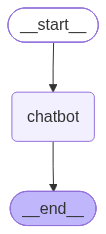

In [3]:
llm = ChatOpenAI(model="gpt-5.4-nano")


def chatbot_node(state: State) -> dict:
    return {"messages": [llm.invoke(state["messages"])]}


builder = StateGraph(State)
builder.add_node("chatbot", chatbot_node)
builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [4]:
result = graph.invoke({"messages": {"role": "user", "content": "What is a directed graph?"}})
console.print(Markdown(result["messages"][-1].content, code_theme="default"))

A directed graph (also called a digraph) is a graph where each edge has a direction.                               

 • It consists of:                                                                                                 
    • Vertices (nodes).                                                                                            
    • Directed edges (arrows) that go from one vertex to another.                                                  
 • An edge from vertex u to vertex v is written as (u → v).                                                        
 • Unlike an undirected graph, (u → v) does not imply (v → u)—the direction matters.                               

Example: If there is an arrow A → B, you can travel from A to B, but not necessarily from B to A.

### Using tools in LangGraph


In [5]:
@tool
def serper_search(query: str) -> str:
    """Search Google using the Serper API."""
    url = "https://google.serper.dev/search"
    headers = {
        "X-API-KEY": os.environ.get("SERPER_API_KEY", ""),
        "Content-Type": "application/json",
    }
    response = requests.post(url, headers=headers, json={"q": query})
    return response.text

In [6]:
@tool
def send_push_notifications(text: str) -> str:
    """Send push notification to mobile"""
    requests.post(
        "https://api.pushover.net/1/messages.json",
        data={
            "token": os.getenv("PUSHOVER_TOKEN"),
            "user": os.getenv("PUSHOVER_USER"),
            "message": text,
        },
    )
    return "Notification sent"

In [7]:
tools = [serper_search, send_push_notifications]
llm_with_tools = llm.bind_tools(tools)

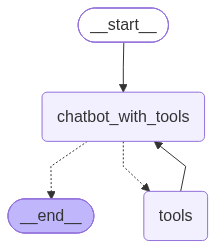

In [8]:
def chatbot_node_with_tools(state: State) -> dict:
    return {"messages": [llm_with_tools.invoke(state["messages"])]}


builder = StateGraph(State)
builder.add_node("chatbot_with_tools", chatbot_node_with_tools)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "chatbot_with_tools")
builder.add_conditional_edges("chatbot_with_tools", tools_condition)
builder.add_edge("tools", "chatbot_with_tools")

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [9]:
result = graph.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "Use search tools to find the recipe of an apple pie and send a notification",
            }
        ]
    }
)
console.print(Markdown(result["messages"][-1].content))

I found an apple pie recipe and sent a notification.                                                               

Recipe link (search result): https://littlespoonfarm.com/apple-pie-recipe/                                         
Notification content: “Apple pie recipe found! Try: slice/prepare apples, toss with sugar + flour + cinnamon/nutmeg
+ lemon, fill crust, top with crust, and bake until golden and bubbly.”

### Building LangGraph Workflows


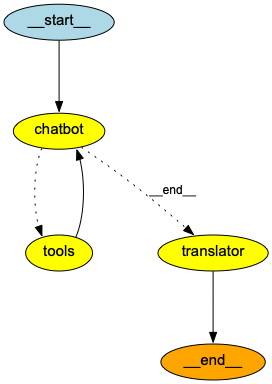

In [ ]:
# Defining the State
class State(TypedDict):
    messages: Annotated[list, add_messages]
    bengali: str


# Define the node function
def translator_node(state: State) -> dict:
    text = state["messages"][-1].content
    prompt = f"Translate this into Bengali, replying with translation only: \n\n{text}"
    return {"bengali": llm.invoke(prompt).content}


# Define the nodes
builder = StateGraph(State)

builder.add_node("chatbot", chatbot_node_with_tools)
builder.add_node("tools", ToolNode(tools))
builder.add_node("translator", translator_node)

# Define the edges
builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", tools_condition, {"tools": "tools", END: "translator"})
builder.add_edge("tools", "chatbot")
builder.add_edge("translator", END)

graph = builder.compile()

display(Image(graph.get_graph().draw_png()))


In [11]:
result = graph.invoke(
    {"messages": [{"role": "user", "content": "What is the minimum age required to vote in US?"}]}
)

console.print(Markdown(result["bengali"]))

যুক্তরাষ্ট্রে, ভোট দেওয়ার সর্বনিম্ন বয়স হলো ১৮ বছর (২৬তম সংশোধনী অনুযায়ী)।